In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = pathlib.Path().resolve().parent
sys.path.insert(0, str(ROOT / "src"))

import const
import json_util
import pde_residual
import pinn_training
import plot_util
import synthetic_taylor_green

plot_util.apply_plot_style()

RESULT = ROOT / "result" / "pinn_viscosity"
RESULT.mkdir(parents=True, exist_ok=True)
FIGURE = RESULT / "figure"
FIGURE.mkdir(exist_ok=True)

RESUME_TRAINING = True

FIELDS = ("u", "v", "w", "p")
DIAG_GRID = (1, 4)
BOUNDS = ([const.TG_X_RANGE[0], const.TG_Y_RANGE[0], const.TG_Z_RANGE[0], const.TG_T_RANGE[0]],
          [const.TG_X_RANGE[1], const.TG_Y_RANGE[1], const.TG_Z_RANGE[1], const.TG_T_RANGE[1]])
INVERSE = {"mu": const.TG_MU_INIT}
KNOWN = {"rho": const.TG_RHO}
TRUE = {"mu": const.TG_MU_TRUE}


def periodic(X_lo, y_lo, X_hi, y_hi):
    return [y_lo[f] - y_hi[f] for f in FIELDS]


def z_neumann(X, y):
    return [pde_residual.grad(y[f], X)[:, 2:3] for f in ("u", "v", "p")] + [y["w"]]


def initial(X, y):
    x, yy = X[:, 0:1], X[:, 1:2]
    return [y["u"] - torch.cos(x) * torch.sin(yy), y["v"] + torch.sin(x) * torch.cos(yy), y["w"],
            y["p"] + 0.25 * const.TG_RHO * (torch.cos(2 * x) + torch.cos(2 * yy))]


BOUNDARY = [{"name": "x_periodic", "axis": 0, "side": "pair", "residual": periodic},
            {"name": "y_periodic", "axis": 1, "side": "pair", "residual": periodic},
            {"name": "z_lo", "axis": 2, "side": "lo", "residual": z_neumann},
            {"name": "z_hi", "axis": 2, "side": "hi", "residual": z_neumann},
            {"name": "initial", "axis": 3, "side": "lo", "residual": initial}]

print("device:", "cuda " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

device: cuda NVIDIA GeForce RTX 5090


# 1. Synthetic Data

In [3]:
dataset = synthetic_taylor_green.sample_synthetic_dataset(
    n_samples=const.TG_N_SAMPLES, mu=const.TG_MU_TRUE, rho=const.TG_RHO,
    x_range=const.TG_X_RANGE, y_range=const.TG_Y_RANGE, z_range=const.TG_Z_RANGE,
    t_range=const.TG_T_RANGE, noise_std=0.0, seed=const.SEED)
print({k: (v.shape if hasattr(v, "shape") else v) for k, v in dataset.items()})

{'X': (3000, 4), 'u': (3000, 1), 'v': (3000, 1), 'w': (3000, 1), 'p': (3000, 1), 'mu_true': 0.05, 'rho': 1.0}


In [4]:
x_lin = np.linspace(*const.TG_X_RANGE, const.TG_GRID_N)
y_lin = np.linspace(*const.TG_Y_RANGE, const.TG_GRID_N)
xg, yg = np.meshgrid(x_lin, y_lin)
check = {"x_lin": x_lin, "y_lin": y_lin, "t_snapshots": list(const.TG_CHECK_T_SNAPSHOTS),
         "exact_u": [], "sample_x": [], "sample_y": [], "sample_u": []}
for t_snap in const.TG_CHECK_T_SNAPSHOTS:
    u_exact, _, _, _ = synthetic_taylor_green.taylor_green_fields(
        xg, yg, np.zeros_like(xg), np.full_like(xg, t_snap), const.TG_MU_TRUE, const.TG_RHO)
    mask = np.abs(dataset["X"][:, 3] - t_snap) <= const.TG_CHECK_T_TOL
    check["exact_u"].append(u_exact)
    check["sample_x"].append(dataset["X"][mask, 0])
    check["sample_y"].append(dataset["X"][mask, 1])
    check["sample_u"].append(dataset["u"][mask, 0])
json_util.save_json(RESULT / "dataset_check.json", check)
print({t: len(sx) for t, sx in zip(check["t_snapshots"], check["sample_x"])})

{0.0: 166, 0.5: 332, 1.0: 153}


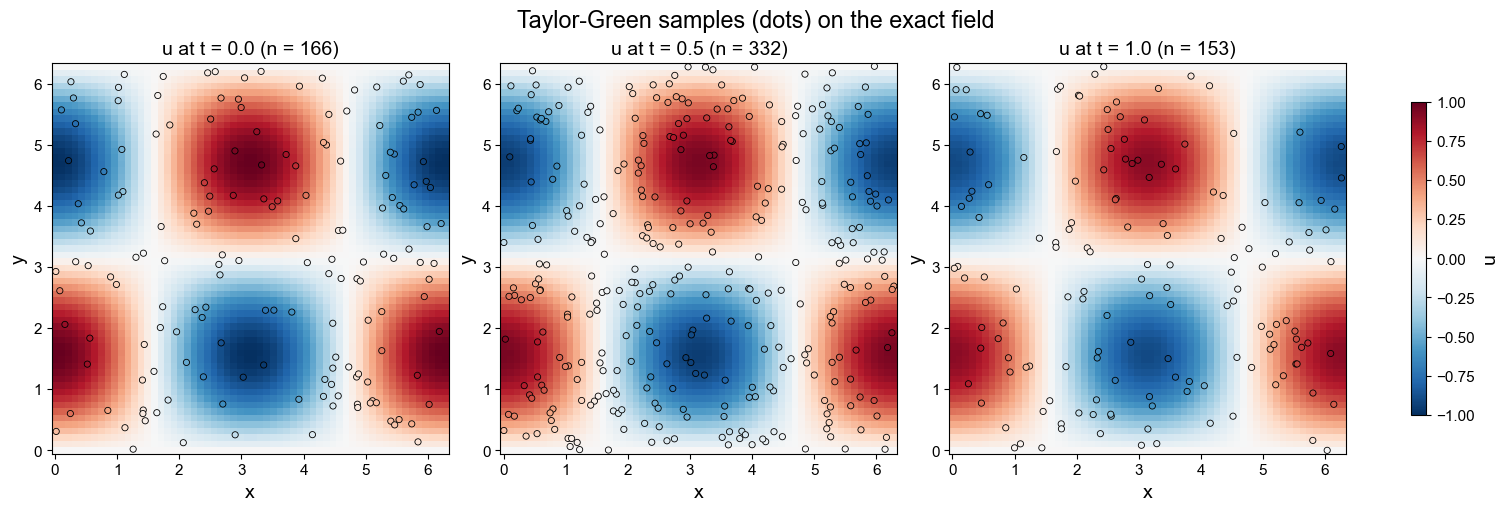

In [5]:
check = json_util.load_json(RESULT / "dataset_check.json")
xg, yg = np.meshgrid(check["x_lin"], check["y_lin"])
n = len(check["t_snapshots"])
fig, axes = plt.subplots(1, n, figsize=(5 * n, 5), constrained_layout=True)
for ax, t_snap, u_exact, sx, sy, su in zip(axes, check["t_snapshots"], check["exact_u"],
                                           check["sample_x"], check["sample_y"], check["sample_u"]):
    im = ax.pcolormesh(xg, yg, u_exact, shading="auto", cmap="RdBu_r", vmin=-1, vmax=1)
    ax.scatter(sx, sy, c=su, cmap="RdBu_r", vmin=-1, vmax=1, s=20, edgecolors="k", linewidths=0.6)
    ax.set_title(f"u at t = {t_snap} (n = {len(sx)})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
fig.colorbar(im, ax=axes, shrink=0.8, label="u")
fig.suptitle("Taylor-Green samples (dots) on the exact field")
fig.savefig(FIGURE / "dataset_check.png")
plt.show()

# 2. Train PINN

In [6]:
RERUN_TRAIN = False
ckpt = RESULT / "main.pt"
path = RESULT / "main.json"
if RERUN_TRAIN or not (ckpt.exists() and path.exists()):
    trainer = pinn_training.PINNTraining(dataset, inverse=INVERSE, known=KNOWN, bounds=BOUNDS, boundary=BOUNDARY,
                                         checkpoint_path=ckpt, resume=RESUME_TRAINING)
    res = trainer.train()
    te = trainer.test_data
    x_lin = np.linspace(*const.TG_X_RANGE, const.TG_GRID_N)
    y_lin = np.linspace(*const.TG_Y_RANGE, const.TG_GRID_N)
    xg, yg = np.meshgrid(x_lin, y_lin)
    grid = np.column_stack([xg.ravel(), yg.ravel(), np.zeros(xg.size), np.full(xg.size, const.TG_RECON_T)])
    u_exact, _, _, _ = synthetic_taylor_green.taylor_green_fields(
        xg, yg, np.zeros_like(xg), np.full_like(xg, const.TG_RECON_T), const.TG_MU_TRUE, const.TG_RHO)
    rec = {"params": res["params"], "true": TRUE,
           "split": {"train": int(trainer.train_data["X"].shape[0]), "valid": int(trainer.valid_data["X"].shape[0]),
                     "test": int(te["X"].shape[0])},
           "n_colloc": res["config"]["n_colloc"],
           "residual": {s: pinn_training.PINNTraining.residual_stats(trainer.evaluate_residual(s))
                        for s in ("train", "valid", "test")},
           "history": res["history"],
           "best": res["best"],
           "test": trainer.diag_record("test"),
           "field": {"t": const.TG_RECON_T, "x_lin": x_lin, "y_lin": y_lin, "exact_u": u_exact,
                     "pred_u": trainer.evaluate(grid)["u"].reshape(xg.shape)},
           "loss": res["loss"], "terms": res["terms"], "wall_seconds": res["wall_seconds"],
           "config": res["config"]}
    json_util.save_json(path, rec)
main = json_util.load_json(path)
print(f"split: {main['split']}   wall: {main['wall_seconds'] / 60:.1f} min   final loss: {main['loss']:.3e}")
for k, v in main["params"].items():
    print(f"{k}: true = {main['true'][k]}   recovered = {v:.5f}   rel_error = {abs(v - main['true'][k]) / main['true'][k]:.2%}")

split: {'train': 2400, 'valid': 300, 'test': 300}   wall: 9.4 min   final loss: 2.307e-06
mu: true = 0.05   recovered = 0.04992   rel_error = 0.15%


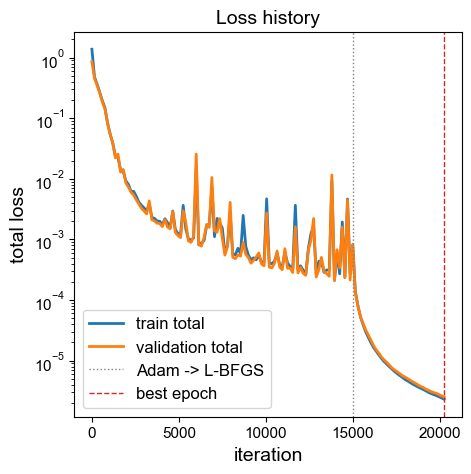

<Axes: title={'center': 'Loss history'}, xlabel='iteration', ylabel='total loss'>

In [7]:
main = json_util.load_json(RESULT / "main.json")
pinn_training.PINNTraining.plot_loss(main["history"], FIGURE / "main_loss.png",
                     best_iteration=main.get("best", {}).get("iteration"))

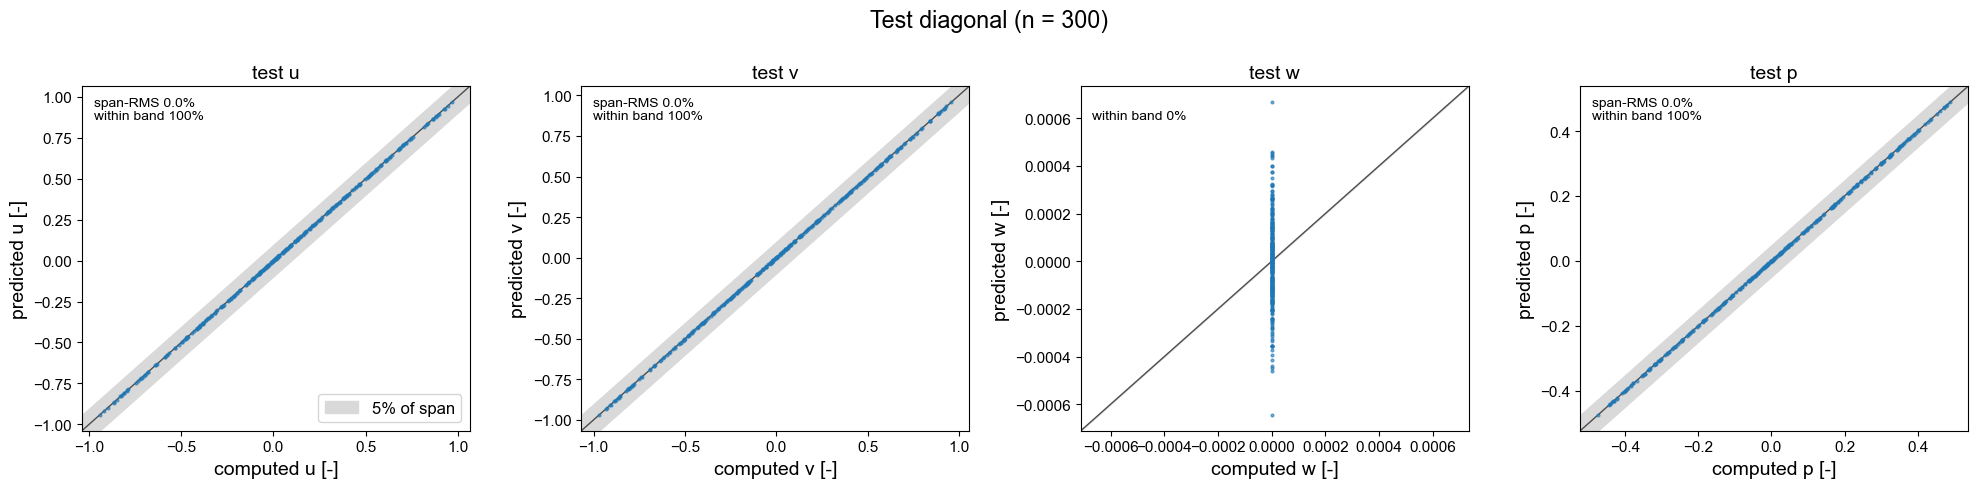

array([<Axes: title={'center': 'test u'}, xlabel='computed u [-]', ylabel='predicted u [-]'>,
       <Axes: title={'center': 'test v'}, xlabel='computed v [-]', ylabel='predicted v [-]'>,
       <Axes: title={'center': 'test w'}, xlabel='computed w [-]', ylabel='predicted w [-]'>,
       <Axes: title={'center': 'test p'}, xlabel='computed p [-]', ylabel='predicted p [-]'>],
      dtype=object)

In [8]:
main = json_util.load_json(RESULT / "main.json")
pinn_training.PINNTraining.plot_diag(main["test"], FIELDS, DIAG_GRID, FIGURE / "main_diag.png",
                     title=f"Test diagonal (n = {main['split']['test']})")

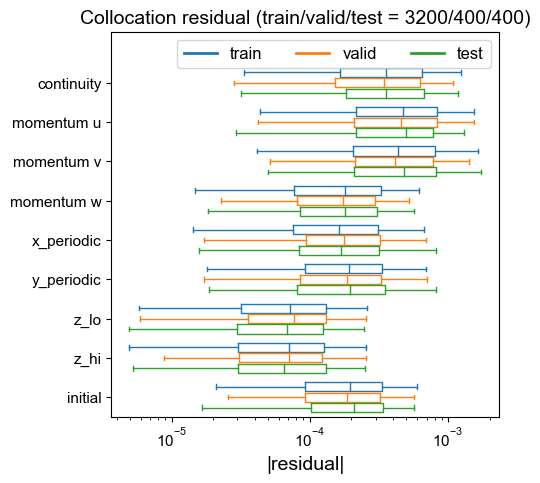

<Axes: title={'center': 'Collocation residual (train/valid/test = 3200/400/400)'}, xlabel='|residual|'>

In [9]:
main = json_util.load_json(RESULT / "main.json")
n_colloc = main["n_colloc"]
pinn_training.PINNTraining.plot_residual(
    main["residual"], FIGURE / "main_residual.png",
    title=f"Collocation residual (train/valid/test = {n_colloc['train']}/{n_colloc['valid']}/{n_colloc['test']})")


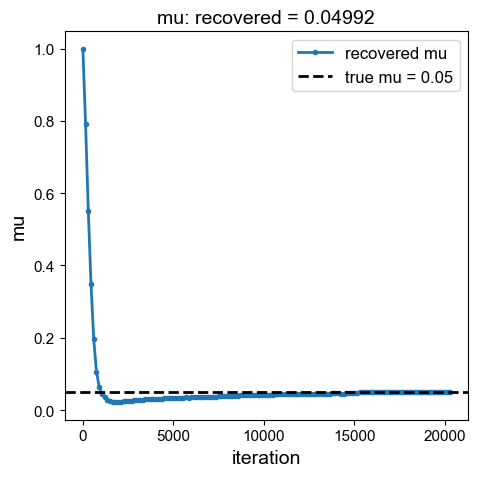

mu: true = 0.05   recovered = 0.04992   rel_error = 0.15%


In [10]:
main = json_util.load_json(RESULT / "main.json")
h = main["history"]
names = list(main["params"])
fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 5), squeeze=False)
for ax, k in zip(axes[0], names):
    ax.plot(h["iteration"], h[k], marker="o", ms=3, label=f"recovered {k}")
    ax.axhline(main["true"][k], color="k", ls="--", label=f"true {k} = {main['true'][k]}")
    ax.set_xlabel("iteration")
    ax.set_ylabel(k)
    ax.set_title(f"{k}: recovered = {main['params'][k]:.5f}")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURE / "main_params.png")
plt.show()
for k in names:
    print(f"{k}: true = {main['true'][k]}   recovered = {main['params'][k]:.5f}   "
          f"rel_error = {abs(main['params'][k] - main['true'][k]) / main['true'][k]:.2%}")

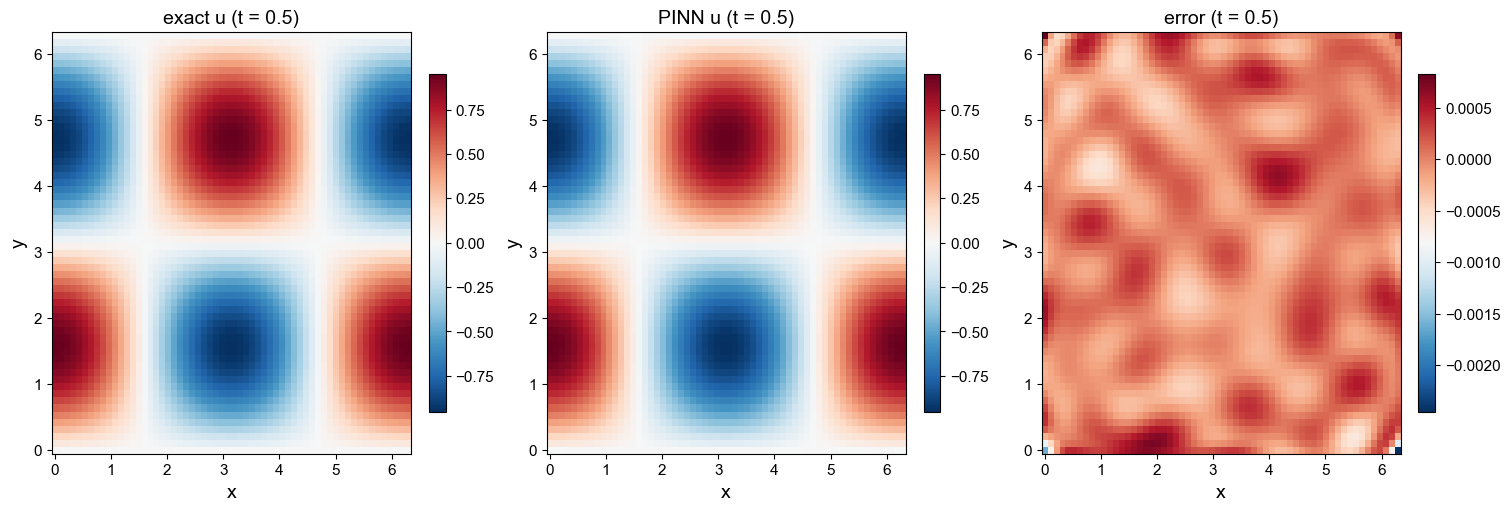

In [11]:
main = json_util.load_json(RESULT / "main.json")
fld = main["field"]
xg, yg = np.meshgrid(fld["x_lin"], fld["y_lin"])
u_true, u_pred = np.asarray(fld["exact_u"]), np.asarray(fld["pred_u"])
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, field, title in zip(axes, [u_true, u_pred, u_pred - u_true], ["exact u", "PINN u", "error"]):
    im = ax.pcolormesh(xg, yg, field, shading="auto", cmap="RdBu_r")
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(f"{title} (t = {fld['t']})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
fig.savefig(FIGURE / "main_field.png")
plt.show()

# 3. Noise Sensitivity

In [12]:
RERUN_NOISE = False
path = RESULT / "noise_sweep.json"
if RERUN_NOISE or not path.exists():
    records = []
    for noise_std in const.NOISE_LEVELS:
        for seed in range(const.N_REPEATS):
            ds = synthetic_taylor_green.sample_synthetic_dataset(
                n_samples=const.TG_N_SAMPLES, mu=const.TG_MU_TRUE, rho=const.TG_RHO,
                x_range=const.TG_X_RANGE, y_range=const.TG_Y_RANGE, z_range=const.TG_Z_RANGE,
                t_range=const.TG_T_RANGE, noise_std=noise_std, seed=seed)
            ckpt = RESULT / "noise_sweep" / f"noise_{noise_std}_seed_{seed}.pt"
            ckpt.parent.mkdir(exist_ok=True)
            trainer = pinn_training.PINNTraining(ds, inverse=INVERSE, known=KNOWN, bounds=BOUNDS, boundary=BOUNDARY,
                                                 adam_iterations=const.SWEEP_ADAM_ITERATIONS,
                                                 lbfgs_iterations=const.SWEEP_LBFGS_ITERATIONS,
                                                 seed=seed, log_every=0,
                                                 checkpoint_path=ckpt, resume=RESUME_TRAINING)
            res = trainer.train()
            records.append({"noise_std": noise_std, "n_samples": const.TG_N_SAMPLES, "seed": seed, "params": res["params"],
                            "best": res["best"],
                            "loss": res["loss"], "val_total": res["history"]["val_total"][-1],
                            "wall_seconds": res["wall_seconds"]})
            print(f"noise_std={records[-1]['noise_std']:<6} seed={seed}  " + "  ".join(
                f"{k}={v:.5f} ({abs(v - TRUE[k]) / TRUE[k]:.2%})" for k, v in res["params"].items()))
    json_util.save_json(path, {"records": records, "true": TRUE})
sweep = json_util.load_json(path)
print(f"{len(sweep['records'])} runs")

12 runs


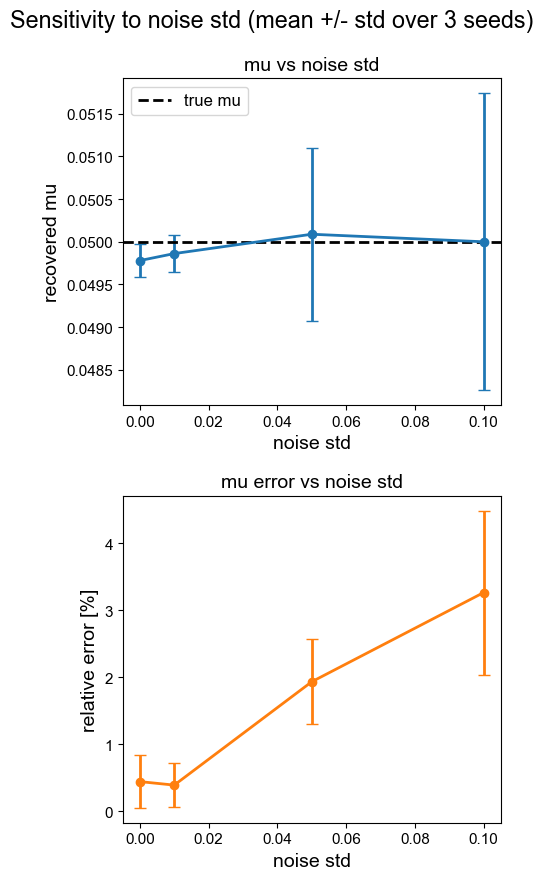

In [13]:
sweep = json_util.load_json(RESULT / "noise_sweep.json")
levels = sorted({r["noise_std"] for r in sweep["records"]})
names = list(sweep["true"])
fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 9), squeeze=False)
for j, k in enumerate(names):
    vals = np.array([[r["params"][k] for r in sweep["records"] if r["noise_std"] == lv] for lv in levels])
    rel = np.abs(vals - sweep["true"][k]) / sweep["true"][k]
    axes[0, j].errorbar(levels, vals.mean(axis=1), yerr=vals.std(axis=1), marker="o", capsize=4)
    axes[0, j].axhline(sweep["true"][k], color="k", ls="--", label=f"true {k}")
    axes[0, j].set_xlabel("noise std")
    axes[0, j].set_ylabel(f"recovered {k}")
    axes[0, j].set_title(f"{k} vs noise std")
    axes[0, j].legend()
    axes[1, j].errorbar(levels, 100 * rel.mean(axis=1), yerr=100 * rel.std(axis=1), marker="o",
                        capsize=4, color="C1")
    axes[1, j].set_xlabel("noise std")
    axes[1, j].set_ylabel("relative error [%]")
    axes[1, j].set_title(f"{k} error vs noise std")
fig.suptitle(f"Sensitivity to noise std (mean +/- std over {const.N_REPEATS} seeds)")
fig.tight_layout()
fig.savefig(FIGURE / "noise_sweep.png")
plt.show()

# 4. Sample Number Sensitivity

In [14]:
RERUN_SAMPLE = False
path = RESULT / "sample_sweep.json"
if RERUN_SAMPLE or not path.exists():
    records = []
    for n_samples in const.SAMPLE_COUNTS:
        for seed in range(const.N_REPEATS):
            ds = synthetic_taylor_green.sample_synthetic_dataset(
                n_samples=n_samples, mu=const.TG_MU_TRUE, rho=const.TG_RHO,
                x_range=const.TG_X_RANGE, y_range=const.TG_Y_RANGE, z_range=const.TG_Z_RANGE,
                t_range=const.TG_T_RANGE, noise_std=0.0, seed=seed)
            ckpt = RESULT / "sample_sweep" / f"n_{n_samples}_seed_{seed}.pt"
            ckpt.parent.mkdir(exist_ok=True)
            trainer = pinn_training.PINNTraining(ds, inverse=INVERSE, known=KNOWN, bounds=BOUNDS, boundary=BOUNDARY,
                                                 adam_iterations=const.SWEEP_ADAM_ITERATIONS,
                                                 lbfgs_iterations=const.SWEEP_LBFGS_ITERATIONS,
                                                 seed=seed, log_every=0,
                                                 checkpoint_path=ckpt, resume=RESUME_TRAINING)
            res = trainer.train()
            records.append({"n_samples": n_samples, "noise_std": 0.0, "seed": seed, "params": res["params"],
                            "best": res["best"],
                            "loss": res["loss"], "val_total": res["history"]["val_total"][-1],
                            "wall_seconds": res["wall_seconds"]})
            print(f"n_samples={records[-1]['n_samples']:<6} seed={seed}  " + "  ".join(
                f"{k}={v:.5f} ({abs(v - TRUE[k]) / TRUE[k]:.2%})" for k, v in res["params"].items()))
    json_util.save_json(path, {"records": records, "true": TRUE})
sweep = json_util.load_json(path)
print(f"{len(sweep['records'])} runs")

15 runs


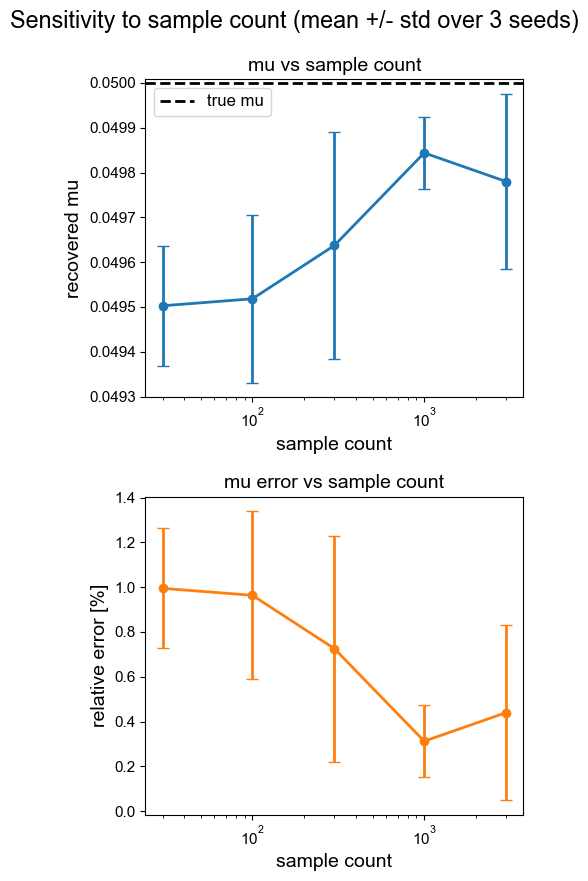

In [15]:
sweep = json_util.load_json(RESULT / "sample_sweep.json")
levels = sorted({r["n_samples"] for r in sweep["records"]})
names = list(sweep["true"])
fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 9), squeeze=False)
for j, k in enumerate(names):
    vals = np.array([[r["params"][k] for r in sweep["records"] if r["n_samples"] == lv] for lv in levels])
    rel = np.abs(vals - sweep["true"][k]) / sweep["true"][k]
    axes[0, j].errorbar(levels, vals.mean(axis=1), yerr=vals.std(axis=1), marker="o", capsize=4)
    axes[0, j].axhline(sweep["true"][k], color="k", ls="--", label=f"true {k}")
    axes[0, j].set_xlabel("sample count")
    axes[0, j].set_ylabel(f"recovered {k}")
    axes[0, j].set_title(f"{k} vs sample count")
    axes[0, j].legend()
    axes[1, j].errorbar(levels, 100 * rel.mean(axis=1), yerr=100 * rel.std(axis=1), marker="o",
                        capsize=4, color="C1")
    axes[1, j].set_xlabel("sample count")
    axes[1, j].set_ylabel("relative error [%]")
    axes[1, j].set_title(f"{k} error vs sample count")
    axes[0, j].set_xscale("log")
    axes[1, j].set_xscale("log")
fig.suptitle(f"Sensitivity to sample count (mean +/- std over {const.N_REPEATS} seeds)")
fig.tight_layout()
fig.savefig(FIGURE / "sample_sweep.png")
plt.show()